### **We use the prtrained model for water mapping**


In [28]:
import torch
import numpy as np
import pandas as pd
import rasterio as rio
from glob import glob
from model import unet
import torch.nn.functional as F
from pyrsimg import imsShow
from processing import config
from pyrsimg import img2patch, metrics_segm, imgShow
from model.mamba_seg.mamba_seg import MambaSeg  
import matplotlib.pyplot as plt

In [2]:
patch_size = 1024        ## patch size setting
## valset
paths_valset = sorted(glob(f'data/dset/val_patch/patch_{patch_size}/*'))  ## for model prediction 
print(f'vali_patch_{patch_size}: {len(paths_valset)}')


vali_patch_1024: 131


In [3]:
## load trained model
path_trained_model = 'model/trained/unet_vmamba_pretrain_1024to256_epoch_305_09128.pth'
model = MambaSeg(in_chans=6, 
                    num_classes=1, 
                    decoder_channels=32, 
                    dims=96,  
                    depths=(2, 2, 8, 2), 
                    backend='torch',
                    # backend='oflex', 
                    pretrained = True
                    )
model.load_state_dict(torch.load(path_trained_model, weights_only=True))
model.eval();  ##  



Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [ ]:
patch_truth = torch.load(paths_valset[0], weights_only=False)        
patch, truth = patch_truth[:-1].float(), patch_truth[-1:]
patch.shape 


torch.Size([6, 1024, 1024])

In [ ]:
pred = model(patch)
pred = F.sigmoid(pred).float()


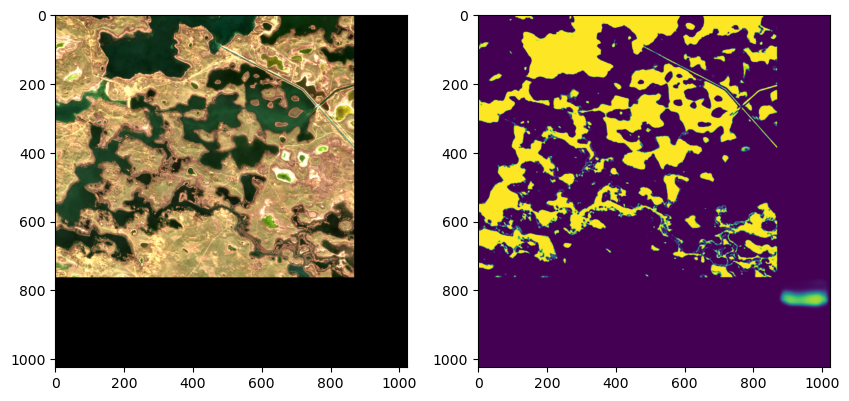

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5)) 
imgShow(patch.numpy().transpose(1,2,0), ax=ax[0])
ax[1].imshow(pred[0].detach().numpy().transpose(1,2,0))
